/tmp/ipython-input-2219980651.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(all_tickers, start=start_date, end=end_date, interval='1mo')['Close']
[*********************100%***********************]  20 of 20 completed


Performance Metrics (Annualized):

Strategy:
  Return: 21.21%
  Std Dev: 22.18%
  Sharpe Ratio: 0.87

Technology:
  Return: 32.70%
  Std Dev: 24.60%
  Sharpe Ratio: 1.25

Financials:
  Return: 19.51%
  Std Dev: 22.01%
  Sharpe Ratio: 0.80

Healthcare:
  Return: 15.36%
  Std Dev: 14.67%
  Sharpe Ratio: 0.91

Equal Weight Portfolio:
  Return: 22.52%
  Std Dev: 16.47%
  Sharpe Ratio: 1.25


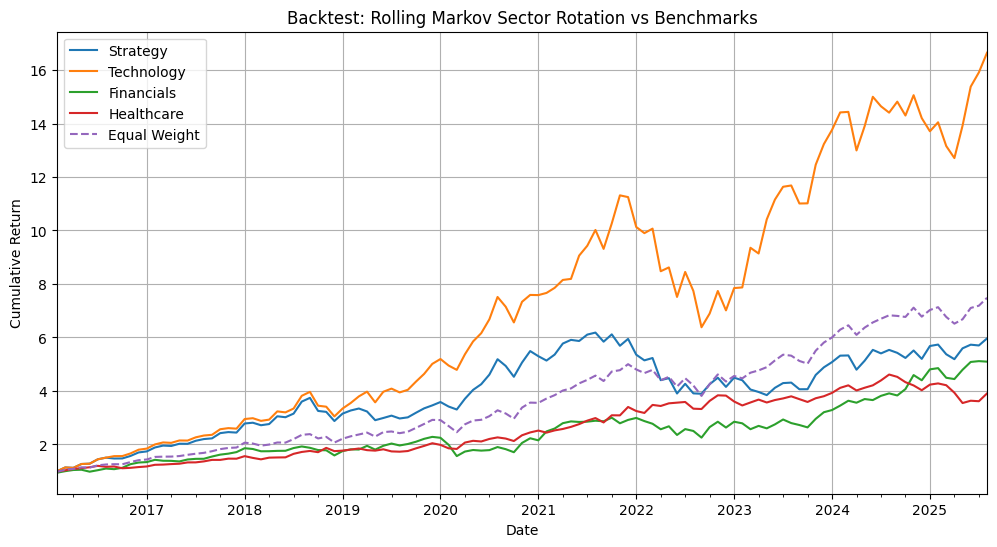

In [54]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define the sectors and their stocks (3 sectors as per user input)
sector_stocks = {
    "Technology": ["AAPL", "NVDA", "MSFT", "AMD", "INTC", "CSCO", "ADBE"],
    "Financials": ["JPM", "V", "MA", "BAC", "WFC", "GS"],
    "Healthcare": ["JNJ", "UNH", "LLY", "PFE", "MRK", "ABBV", "TMO"]
}

sectors = list(sector_stocks.keys())
num_sectors = len(sectors)

# Fetch monthly adjusted close prices from yfinance
all_tickers = [ticker for stocks in sector_stocks.values() for ticker in stocks]
start_date = '2015-01-01'  # Extended start date for sufficient history
end_date = '2025-08-16'    # Adjust if running after this date
prices = yf.download(all_tickers, start=start_date, end=end_date, interval='1mo')['Close']

# Compute monthly returns
returns = prices.pct_change().dropna()

# Compute equal-weighted sector returns
sector_returns = pd.DataFrame({
    sector: returns[stocks].mean(axis=1)
    for sector, stocks in sector_stocks.items()
})

# Identify the top-performing sector each month
top_sectors = sector_returns.idxmax(axis=1)

# Parameters
lookback_months = 12  # 2 years
initial_held = "Technology"  # Starting sector
risk_free_rate = 0.02  # Annual risk-free rate
annual_factor = 12     # For monthly data

# Backtest starts after initial lookback period
start_idx = lookback_months
strategy_returns = pd.Series(index=sector_returns.index[start_idx:], dtype=float)
held = initial_held

# Function to compute prediction map from transition probs
def get_prediction_map(transition_probs, sectors):
    prediction_map = {}
    for i, sector in enumerate(sectors):
        row = transition_probs[i]
        if np.all(np.isnan(row)):
            prediction_map[sector] = sector  # Stay if no data
        else:
            prediction_map[sector] = sectors[np.nanargmax(row)]
    return prediction_map

for idx in range(start_idx, len(sector_returns)):
    date = sector_returns.index[idx]

    # Earn the return of the currently held sector for this month
    strategy_returns.loc[date] = sector_returns.loc[date, held]

    # Update held sector for next month
    this_best = top_sectors.loc[date]
    if held == this_best:
        continue  # Keep current if it's the best

    # Compute rolling Markov chain based on previous lookback months
    rolling_top = top_sectors.iloc[idx - lookback_months:idx]
    transition_counts = np.zeros((num_sectors, num_sectors), dtype=int)

    for i in range(len(rolling_top) - 1):
        current = rolling_top.iloc[i]
        next_sector = rolling_top.iloc[i + 1]
        current_idx = sectors.index(current)
        next_idx = sectors.index(next_sector)
        transition_counts[current_idx, next_idx] += 1

    row_sums = transition_counts.sum(axis=1, keepdims=True)
    transition_probs = np.divide(transition_counts, row_sums, where=row_sums != 0)
    transition_probs[row_sums.squeeze() == 0] = np.nan

    # Get dynamic prediction map
    prediction_map = get_prediction_map(transition_probs, sectors)

    # Switch to predicted sector based on this_best
    held = prediction_map.get(this_best, held)  # Fallback to current if not found

# Compute equal-weighted portfolio returns (benchmark) for the backtest period
equal_returns = sector_returns.iloc[start_idx:].mean(axis=1)

# Function to calculate metrics: annualized return, std, Sharpe
def calculate_metrics(returns_series):
    mean_return = returns_series.mean() * annual_factor
    std_dev = returns_series.std() * np.sqrt(annual_factor)
    sharpe = (mean_return - risk_free_rate) / std_dev if std_dev != 0 else np.nan
    return mean_return, std_dev, sharpe

# Calculate metrics for strategy
strat_mean, strat_std, strat_sharpe = calculate_metrics(strategy_returns)

# Calculate metrics for each sector (over backtest period)
sector_metrics = {
    sector: calculate_metrics(sector_returns[sector].iloc[start_idx:])
    for sector in sectors
}

# Calculate metrics for equal-weight portfolio
equal_mean, equal_std, equal_sharpe = calculate_metrics(equal_returns)

# Compute cumulative returns for plotting
strategy_cum = (1 + strategy_returns).cumprod()
sector_cum = (1 + sector_returns.iloc[start_idx:]).cumprod()
equal_cum = (1 + equal_returns).cumprod()

# Print results
print("Performance Metrics (Annualized):")
print(f"\nStrategy:")
print(f"  Return: {strat_mean*100:.2f}%")
print(f"  Std Dev: {strat_std*100:.2f}%")
print(f"  Sharpe Ratio: {strat_sharpe:.2f}")
for sector in sectors:
    mean, std, sharpe = sector_metrics[sector]
    print(f"\n{sector}:")
    print(f"  Return: {mean*100:.2f}%")
    print(f"  Std Dev: {std*100:.2f}%")
    print(f"  Sharpe Ratio: {sharpe:.2f}")
print(f"\nEqual Weight Portfolio:")
print(f"  Return: {equal_mean*100:.2f}%")
print(f"  Std Dev: {equal_std*100:.2f}%")
print(f"  Sharpe Ratio: {equal_sharpe:.2f}")

# Plot cumulative returns
plt.figure(figsize=(12, 6))
strategy_cum.plot(label='Strategy')
for sector in sectors:
    sector_cum[sector].plot(label=sector)
equal_cum.plot(label='Equal Weight', linestyle='--')
plt.title('Backtest: Rolling Markov Sector Rotation vs Benchmarks')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True)
plt.show()

/tmp/ipython-input-2908099367.py:45: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(all_tickers, start=start_date, end=end_date, interval='1mo')['Close']
[*********************100%***********************]  28 of 28 completed


Ticker           BZ=F    CC=F       CL=F       CT=F       DC=F         GC=F  \
Date                                                                          
2015-01-01  52.990002  2693.0  48.240002  59.360001  16.139999  1278.500000   
2015-04-01  66.779999  2943.0  59.630001  68.120003  16.219999  1182.400024   
2015-05-01  65.559998  3085.0  60.299999  64.349998  16.219999  1189.400024   
2015-06-01  63.590000  3275.0  59.470001  67.510002  16.709999  1171.500000   
2015-07-01  52.209999  3209.0  47.119999  64.010002  16.410000  1094.900024   
...               ...     ...        ...        ...        ...          ...   
2025-03-01  74.739998  7902.0  71.480003  66.830002  18.660000  3122.800049   
2025-04-01  63.119999  9127.0  58.209999  65.769997  18.370001  3305.000000   
2025-05-01  63.900002  9791.0  60.790001  65.059998  18.620001  3288.899902   
2025-07-01  72.529999  8506.0  69.260002  65.610001  17.129999  3293.199951   
2025-08-01  66.160004  8281.0  63.139999  66.059998 

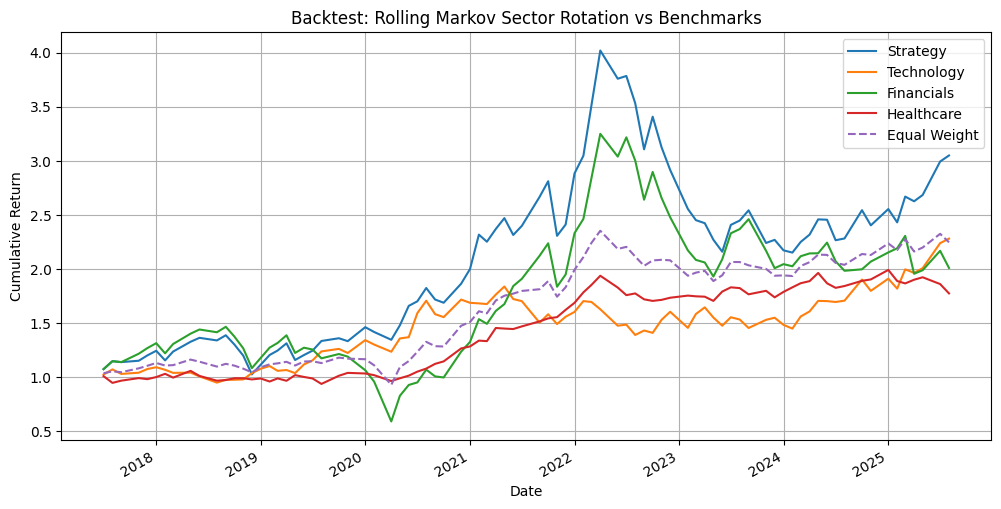

In [55]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define the sectors and their stocks (3 sectors as per user input)
sector_stocks = {
    "Technology": ["GC=F",  # Gold
    "MGC=F",  # Micro Gold
    "SI=F",  # Silver
    "SIL=F",  # Micro Silver
    "PL=F",  # Platinum
    "PA=F"],
    "Financials": ["CL=F",  # Crude Oil (WTI)
    "BZ=F",  # Brent Crude Oil
    "HO=F",  # Heating Oil
    "NG=F",  # Natural Gas
    "RB=F"],
    "Healthcare": ["ZC=F",  # Corn
    "ZO=F",  # Oats
    "ZR=F",  # Rough Rice
    "ZS=F",  # Soybeans
    "ZM=F",  # Soybean Meal
    "ZL=F",  # Soybean Oil
    "ZW=F",  # Wheat
    "KE=F",  # KC HRW Wheat
    "CC=F",  # Cocoa
    "KC=F",  # Coffee
    "CT=F",  # Cotton
    "SB=F",  # Sugar #11
    "OJ=F",  # Orange Juice
    "HE=F",  # Lean Hogs
    "LE=F",  # Live Cattle
    "GF=F",  # Feeder Cattle
    "DC=F"]
}

sectors = list(sector_stocks.keys())
num_sectors = len(sectors)

# Fetch monthly adjusted close prices from yfinance
all_tickers = [ticker for stocks in sector_stocks.values() for ticker in stocks]
start_date = '2015-01-01'  # Extended start date for sufficient history
end_date = '2025-08-16'    # Adjust if running after this date
prices = yf.download(all_tickers, start=start_date, end=end_date, interval='1mo')['Close']
print(prices)
# Compute monthly returns
returns = prices.pct_change().dropna()

# Compute equal-weighted sector returns
sector_returns = pd.DataFrame({
    sector: returns[stocks].mean(axis=1)
    for sector, stocks in sector_stocks.items()
})

# Identify the top-performing sector each month
top_sectors = sector_returns.idxmax(axis=1)

# Parameters
lookback_months = 24  # 2 years
initial_held = "Financials"  # Starting sector
risk_free_rate = 0.02  # Annual risk-free rate
annual_factor = 12     # For monthly data

# Backtest starts after initial lookback period
start_idx = lookback_months
strategy_returns = pd.Series(index=sector_returns.index[start_idx:], dtype=float)
held = initial_held

# Function to compute prediction map from transition probs
def get_prediction_map(transition_probs, sectors):
    prediction_map = {}
    for i, sector in enumerate(sectors):
        row = transition_probs[i]
        if np.all(np.isnan(row)):
            prediction_map[sector] = sector  # Stay if no data
        else:
            prediction_map[sector] = sectors[np.nanargmax(row)]
    print (prediction_map)
    return prediction_map

for idx in range(start_idx, len(sector_returns)):
    date = sector_returns.index[idx]

    # Earn the return of the currently held sector for this month
    strategy_returns.loc[date] = sector_returns.loc[date, held]

    # Update held sector for next month
    this_best = top_sectors.loc[date]
    if held == this_best:
        continue  # Keep current if it's the best

    # Compute rolling Markov chain based on previous lookback months
    rolling_top = top_sectors.iloc[idx - lookback_months:idx]
    transition_counts = np.zeros((num_sectors, num_sectors), dtype=int)

    for i in range(len(rolling_top) - 1):
        current = rolling_top.iloc[i]
        next_sector = rolling_top.iloc[i + 1]
        current_idx = sectors.index(current)
        next_idx = sectors.index(next_sector)
        transition_counts[current_idx, next_idx] += 1

    row_sums = transition_counts.sum(axis=1, keepdims=True)
    transition_probs = np.divide(transition_counts, row_sums, where=row_sums != 0)
    transition_probs[row_sums.squeeze() == 0] = np.nan

    # Get dynamic prediction map
    prediction_map = get_prediction_map(transition_probs, sectors)

    # Switch to predicted sector based on this_best
    held = prediction_map.get(this_best, held)  # Fallback to current if not found

# Compute equal-weighted portfolio returns (benchmark) for the backtest period
equal_returns = sector_returns.iloc[start_idx:].mean(axis=1)

# Function to calculate metrics: annualized return, std, Sharpe
def calculate_metrics(returns_series):
    mean_return = returns_series.mean() * annual_factor
    std_dev = returns_series.std() * np.sqrt(annual_factor)
    sharpe = (mean_return - risk_free_rate) / std_dev if std_dev != 0 else np.nan
    return mean_return, std_dev, sharpe

# Calculate metrics for strategy
strat_mean, strat_std, strat_sharpe = calculate_metrics(strategy_returns)

# Calculate metrics for each sector (over backtest period)
sector_metrics = {
    sector: calculate_metrics(sector_returns[sector].iloc[start_idx:])
    for sector in sectors
}

# Calculate metrics for equal-weight portfolio
equal_mean, equal_std, equal_sharpe = calculate_metrics(equal_returns)

# Compute cumulative returns for plotting
strategy_cum = (1 + strategy_returns).cumprod()
sector_cum = (1 + sector_returns.iloc[start_idx:]).cumprod()
equal_cum = (1 + equal_returns).cumprod()

# Print results
print("Performance Metrics (Annualized):")
print(f"\nStrategy:")
print(f"  Return: {strat_mean*100:.2f}%")
print(f"  Std Dev: {strat_std*100:.2f}%")
print(f"  Sharpe Ratio: {strat_sharpe:.2f}")
for sector in sectors:
    mean, std, sharpe = sector_metrics[sector]
    print(f"\n{sector}:")
    print(f"  Return: {mean*100:.2f}%")
    print(f"  Std Dev: {std*100:.2f}%")
    print(f"  Sharpe Ratio: {sharpe:.2f}")
print(f"\nEqual Weight Portfolio:")
print(f"  Return: {equal_mean*100:.2f}%")
print(f"  Std Dev: {equal_std*100:.2f}%")
print(f"  Sharpe Ratio: {equal_sharpe:.2f}")

# Plot cumulative returns
plt.figure(figsize=(12, 6))
strategy_cum.plot(label='Strategy')
for sector in sectors:
    sector_cum[sector].plot(label=sector)
equal_cum.plot(label='Equal Weight', linestyle='--')
plt.title('Backtest: Rolling Markov Sector Rotation vs Benchmarks')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True)
plt.show()

/tmp/ipython-input-1118091790.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(all_tickers, start=start_date, end=end_date, interval='1d')['Close']
[*********************100%***********************]  3 of 3 completed
/tmp/ipython-input-1118091790.py:23: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = prices.pct_change().dropna()


Ticker            BTC-USD         GC=F         SPY
Date                                              
2018-01-01   13657.200195          NaN         NaN
2018-01-02   14982.099609  1313.699951  238.568710
2018-01-03   15201.000000  1316.199951  240.077728
2018-01-04   15599.200195  1319.400024  241.089645
2018-01-05   17429.500000  1320.300049  242.696274
...                   ...          ...         ...
2025-08-11  118731.445312  3353.100098  635.919983
2025-08-12  120172.906250  3348.899902  642.690002
2025-08-13  123344.062500  3358.699951  644.890015
2025-08-14  118359.578125  3335.199951  644.950012
2025-08-15            NaN  3336.000000  643.440002

[2784 rows x 3 columns]
{'Technology': 'Technology', 'Financials': 'Technology', 'Healthcare': 'Financials'}
{'Technology': 'Technology', 'Financials': 'Technology', 'Healthcare': 'Financials'}
{'Technology': 'Technology', 'Financials': 'Technology', 'Healthcare': 'Financials'}
{'Technology': 'Technology', 'Financials': 'Technology', 

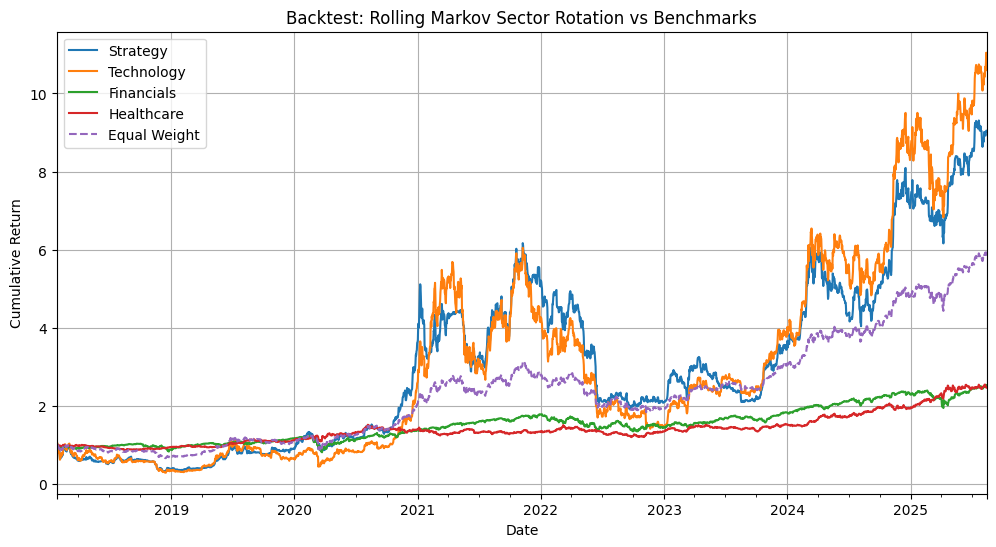

In [58]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define the sectors and their stocks (3 sectors as per user input)
sector_stocks = {
    "Technology": ["BTC-USD"],
    "Financials": ["SPY"],
    "Healthcare": ["GC=F"]
}

sectors = list(sector_stocks.keys())
num_sectors = len(sectors)

# Fetch monthly adjusted close prices from yfinance
all_tickers = [ticker for stocks in sector_stocks.values() for ticker in stocks]
start_date = '2018-01-01'  # Extended start date for sufficient history
end_date = '2025-08-16'    # Adjust if running after this date
prices = yf.download(all_tickers, start=start_date, end=end_date, interval='1d')['Close']
print(prices)
# Compute monthly returns
returns = prices.pct_change().dropna()

# Compute equal-weighted sector returns
sector_returns = pd.DataFrame({
    sector: returns[stocks].mean(axis=1)
    for sector, stocks in sector_stocks.items()
})

# Identify the top-performing sector each month
top_sectors = sector_returns.idxmax(axis=1)

# Parameters
lookback_months = 24  # 2 years
initial_held = "Financials"  # Starting sector
risk_free_rate = 0.02  # Annual risk-free rate
annual_factor = 12     # For monthly data

# Backtest starts after initial lookback period
start_idx = lookback_months
strategy_returns = pd.Series(index=sector_returns.index[start_idx:], dtype=float)
held = initial_held

# Function to compute prediction map from transition probs
def get_prediction_map(transition_probs, sectors):
    prediction_map = {}
    for i, sector in enumerate(sectors):
        row = transition_probs[i]
        if np.all(np.isnan(row)):
            prediction_map[sector] = sector  # Stay if no data
        else:
            prediction_map[sector] = sectors[np.nanargmax(row)]
    print (prediction_map)
    return prediction_map

for idx in range(start_idx, len(sector_returns)):
    date = sector_returns.index[idx]

    # Earn the return of the currently held sector for this month
    strategy_returns.loc[date] = sector_returns.loc[date, held]

    # Update held sector for next month
    this_best = top_sectors.loc[date]
    if held == this_best:
        continue  # Keep current if it's the best

    # Compute rolling Markov chain based on previous lookback months
    rolling_top = top_sectors.iloc[idx - lookback_months:idx]
    transition_counts = np.zeros((num_sectors, num_sectors), dtype=int)

    for i in range(len(rolling_top) - 1):
        current = rolling_top.iloc[i]
        next_sector = rolling_top.iloc[i + 1]
        current_idx = sectors.index(current)
        next_idx = sectors.index(next_sector)
        transition_counts[current_idx, next_idx] += 1

    row_sums = transition_counts.sum(axis=1, keepdims=True)
    transition_probs = np.divide(transition_counts, row_sums, where=row_sums != 0)
    transition_probs[row_sums.squeeze() == 0] = np.nan

    # Get dynamic prediction map
    prediction_map = get_prediction_map(transition_probs, sectors)

    # Switch to predicted sector based on this_best
    held = prediction_map.get(this_best, held)  # Fallback to current if not found

# Compute equal-weighted portfolio returns (benchmark) for the backtest period
equal_returns = sector_returns.iloc[start_idx:].mean(axis=1)

# Function to calculate metrics: annualized return, std, Sharpe
def calculate_metrics(returns_series):
    mean_return = returns_series.mean() * annual_factor
    std_dev = returns_series.std() * np.sqrt(annual_factor)
    sharpe = (mean_return - risk_free_rate) / std_dev if std_dev != 0 else np.nan
    return mean_return, std_dev, sharpe

# Calculate metrics for strategy
strat_mean, strat_std, strat_sharpe = calculate_metrics(strategy_returns)

# Calculate metrics for each sector (over backtest period)
sector_metrics = {
    sector: calculate_metrics(sector_returns[sector].iloc[start_idx:])
    for sector in sectors
}

# Calculate metrics for equal-weight portfolio
equal_mean, equal_std, equal_sharpe = calculate_metrics(equal_returns)

# Compute cumulative returns for plotting
strategy_cum = (1 + strategy_returns).cumprod()
sector_cum = (1 + sector_returns.iloc[start_idx:]).cumprod()
equal_cum = (1 + equal_returns).cumprod()

# Print results
print("Performance Metrics (Annualized):")
print(f"\nStrategy:")
print(f"  Return: {strat_mean*100:.2f}%")
print(f"  Std Dev: {strat_std*100:.2f}%")
print(f"  Sharpe Ratio: {strat_sharpe:.2f}")
for sector in sectors:
    mean, std, sharpe = sector_metrics[sector]
    print(f"\n{sector}:")
    print(f"  Return: {mean*100:.2f}%")
    print(f"  Std Dev: {std*100:.2f}%")
    print(f"  Sharpe Ratio: {sharpe:.2f}")
print(f"\nEqual Weight Portfolio:")
print(f"  Return: {equal_mean*100:.2f}%")
print(f"  Std Dev: {equal_std*100:.2f}%")
print(f"  Sharpe Ratio: {equal_sharpe:.2f}")

# Plot cumulative returns
plt.figure(figsize=(12, 6))
strategy_cum.plot(label='Strategy')
for sector in sectors:
    sector_cum[sector].plot(label=sector)
equal_cum.plot(label='Equal Weight', linestyle='--')
plt.title('Backtest: Rolling Markov Sector Rotation vs Benchmarks')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True)
plt.show()